In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 51.4 MB/s  0:00:01


# Task 01 — Stroke Prediction (Classification)
**Goal:** predict whether a patient will have a stroke. **Target:** `stroke` (1 = stroke). **Features:** gender, age, hypertension, heart_disease, ever_married, work_type, Residence_type, avg_glucose_level, bmi, smoking_status.

**Important:** only ~5% of the patients have a stroke (imbalanced data), so *Accuracy is misleading* (always predicting "no stroke" gives ~95%). We look at **Recall, F1, ROC-AUC and PR-AUC** instead.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

## 1. Load the data

In [3]:
import os
path = 'dataset/healthcare-dataset-stroke-data.csv'
if not os.path.exists(path):          # e.g. file uploaded next to the notebook (Colab)
    path = 'healthcare-dataset-stroke-data.csv'
df = pd.read_csv(path)

In [4]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [5]:
df.shape

(5110, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [7]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [8]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

## 2. Data cleaning

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.drop_duplicates()

In [11]:
df.reset_index(drop=True,inplace=True)

In [12]:
df.isnull().sum().sort_values(ascending=False).head()

,0
bmi,201
id,0
age,0
gender,0
hypertension,0


In [13]:
# bmi has missing values. They are filled AFTER the train/test split (using the train data only)
print("Missing bmi values:", df['bmi'].isnull().sum())

Missing bmi values: 201


In [14]:
(df[['bmi']].isnull().sum())

,0
bmi,201


### Outliers (IQR rule)

In [15]:
for col in ['age', 'avg_glucose_level', 'bmi']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / len(df) * 100:.1f}%)  [valid range {low:.1f} to {high:.1f}]")

age: 0 outliers (0.0%)  [valid range -29.0 to 115.0]
avg_glucose_level: 627 outliers (12.3%)  [valid range 22.0 to 169.4]
bmi: 110 outliers (2.2%)  [valid range 9.1 to 47.5]


**Decision:** the outliers are *kept*. High glucose / high BMI are real medical values (diabetic or obese patients) and these are exactly the patients with higher stroke risk, so deleting them would remove useful information. Scaling is applied later and the tree models are not sensitive to outliers.

## 3. EDA (visualization)

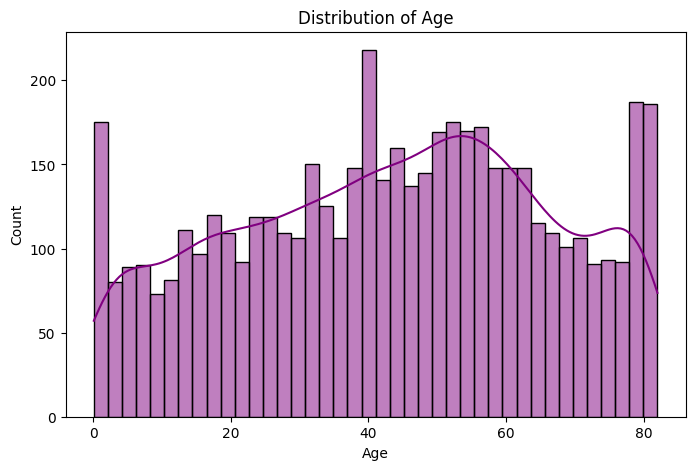

In [16]:
plt.figure(figsize=(8, 5))
sns.histplot(df['age'], bins=40, kde=True, color='purple')
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

/tmp/ipykernel_488/6836335.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='stroke', y='age', data=df, palette='Set2')


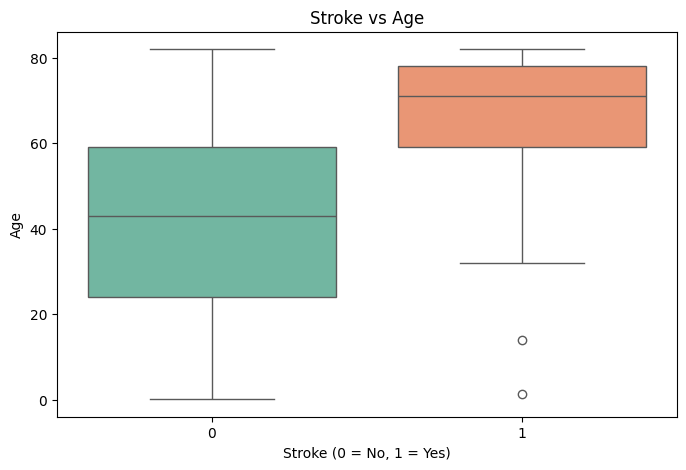

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='stroke', y='age', data=df, palette='Set2')
plt.title('Stroke vs Age')
plt.xlabel('Stroke (0 = No, 1 = Yes)')
plt.ylabel('Age')
plt.show()

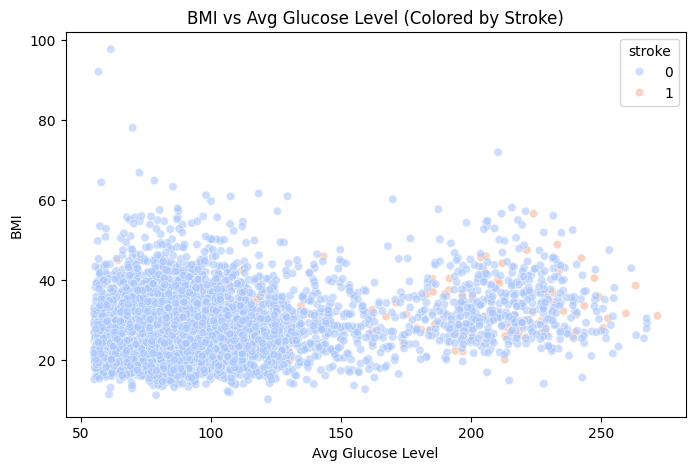

In [18]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df, hue='stroke', alpha=0.6, palette='coolwarm')
plt.title('BMI vs Avg Glucose Level (Colored by Stroke)')
plt.xlabel('Avg Glucose Level')
plt.ylabel('BMI')
plt.show()

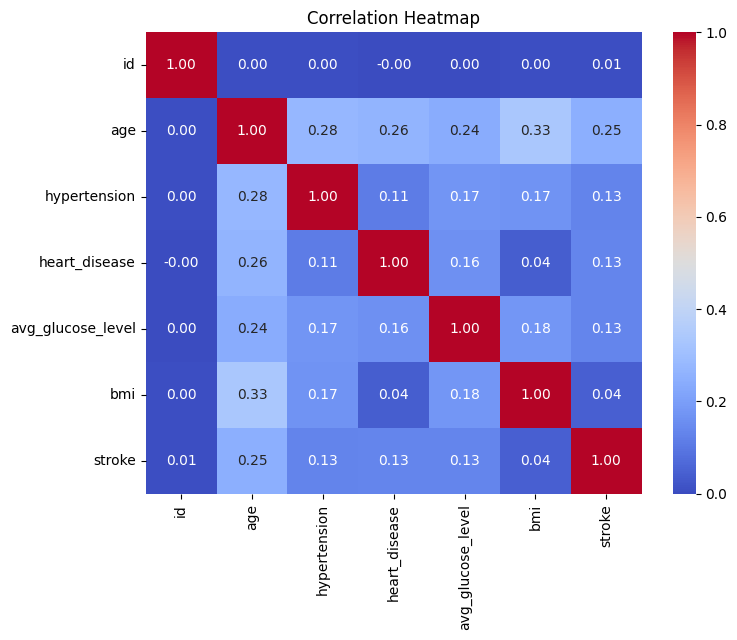

In [19]:
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## 4. Encoding

In [20]:
df_encoded = pd.get_dummies(df, columns=['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status'], drop_first=True)

print("Shape before encoding:", df.shape)
print("Shape after encoding:", df_encoded.shape)

Shape before encoding: (5110, 12)
Shape after encoding: (5110, 18)


In [21]:
X = df_encoded.drop(columns=['stroke', 'id'], errors='ignore')
y = df_encoded['stroke']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5110, 16)
y shape: (5110,)


## 5. Train / Test split
A stratified split keeps the same stroke percentage in train and test (the old split used 50% test and no stratify).

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (4088, 16)
X_test shape: (1022, 16)


### Fill missing bmi (fit on the train data only, then apply to test) -> no data leakage

In [23]:
from sklearn.impute import SimpleImputer

X_train = X_train.copy()
X_test = X_test.copy()

imputer_bmi = SimpleImputer(strategy='median')
X_train[['bmi']] = imputer_bmi.fit_transform(X_train[['bmi']])
X_test[['bmi']] = imputer_bmi.transform(X_test[['bmi']])

print("Missing values left:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Missing values left: 0 0


## 6. Scaling (fit on train only)

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Mean of scaled X_train:", round(X_train_scaled.mean(), 5))
print("Std of scaled X_train:", round(X_train_scaled.std(), 5))

Mean of scaled X_train: -0.0
Std of scaled X_train: 1.0


In [25]:
# use the scaled data for ALL the models below (KNN, SVM, Logistic Regression need scaling)
X_train = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

## 7. Logistic Regression + handling the imbalance
We try: normal data, SMOTE (over sampling), random under sampling and class weights.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [27]:
model = LogisticRegression(class_weight={0: 1, 1: 5}, C=0.1, max_iter=1000)
model.fit(X_train_scaled, y_train)

LogisticRegression(C=0.1, class_weight={0: 1, 1: 5}, max_iter=1000)

In [28]:
y_pred = model.predict(X_test_scaled)

In [29]:
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.97      0.93      0.95       972
           1       0.28      0.50      0.36        50

    accuracy                           0.91      1022
   macro avg       0.63      0.72      0.65      1022
weighted avg       0.94      0.91      0.92      1022



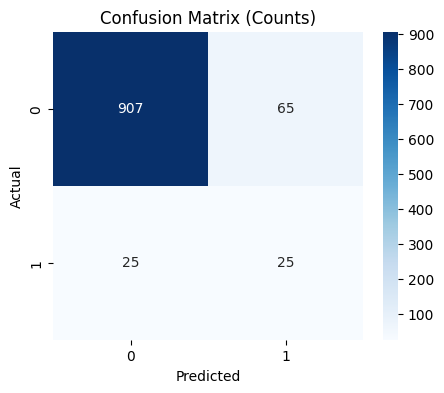

In [30]:
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (Counts)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

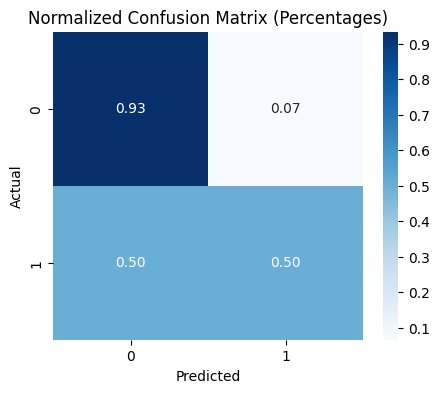

In [31]:
plt.figure(figsize=(5, 4))
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')
sns.heatmap(cm_norm, annot=True, fmt='0.2f', cmap='Blues')
plt.title('Normalized Confusion Matrix (Percentages)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [32]:
metrics_df = pd.DataFrame(
    [[accuracy_score(y_test, y_pred),
      precision_score(y_test, y_pred),
      recall_score(y_test, y_pred),
      f1_score(y_test, y_pred)]],
    index=['Logistic Regression'],
    columns=['Accuracy', 'Precision', 'Recall', 'F1-Score']
)

display(metrics_df)

,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.911937,0.277778,0.5,0.357143


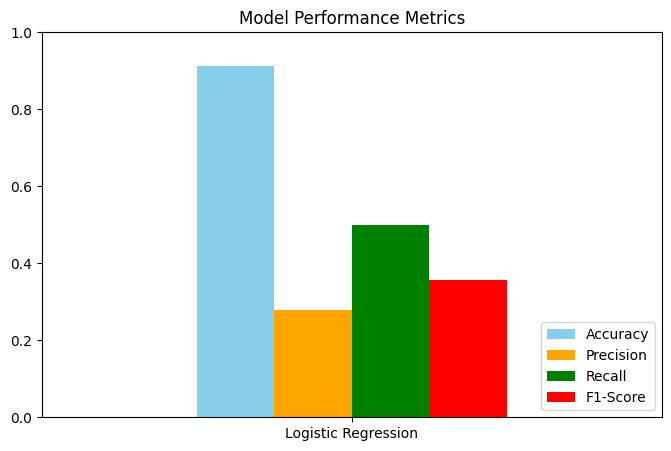

In [33]:
metrics_df.plot(kind='bar', figsize=(8, 5), color=['skyblue', 'orange', 'green', 'red'])
plt.title('Model Performance Metrics')
plt.ylim(0, 1.0)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [34]:
results = []

# Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [35]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("X_train_smote = ",X_train_smote.shape ," y_train_smote = ", y_train_smote.shape)

X_train_smote =  (7778, 16)  y_train_smote =  (7778,)


In [36]:
y_train_smote.value_counts()

,count
stroke,
0,3889
1,3889


In [37]:
# Logistic Regression Using Smote Over Sampling
model = LogisticRegression()
model.fit(X_train_smote, y_train_smote)
y_pred = model.predict(X_test)

results.append({
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

# Under Sampling

In [38]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("X_train_rus = ",X_train_rus.shape ," y_train_rus = ", y_train_rus.shape)

X_train_rus =  (398, 16)  y_train_rus =  (398,)


In [39]:
y_train_rus.value_counts()

,count
stroke,
0,199
1,199


In [40]:
# Logistic Regression Using Random Under Sampling
model = LogisticRegression()
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test)

results.append({
    'Method': "Random Under Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

# Class Weights

In [41]:
# Logistic Regression Using Class Weight Balanced

model = LogisticRegression(class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [42]:
# Logistic Regression Using Class Weight Balanced

model = LogisticRegression(class_weight={0:1,1:10})
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Class Weight Balanced Custom",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [43]:
np.unique(y_train)

array([0, 1])

In [44]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy,Precision,Recall,F1-Score
Method,,,,
Normal Data,0.952055,1.000000,0.02,0.039216
SMOTE Over Sampling,0.750489,0.140351,0.80,0.238806
Random Under Sampling,0.734834,0.135314,0.82,0.232295
Class Weight Balanced,0.746575,0.138408,0.80,0.235988
Class Weight Balanced Custom,0.839530,0.196809,0.74,0.310924


**Reading the table:** with normal data the recall is almost 0 (the model says "no stroke" to everybody). Class weights / sampling raise the recall a lot, with lower precision. For a medical screening problem, catching real stroke cases (recall) matters more than a few false alarms.

## 8. All the models
All models of the track are trained on the scaled data and evaluated on the test set (confusion matrix, classification report, ROC curve, PR curve).

In [45]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[972   0]
 [ 49   1]]


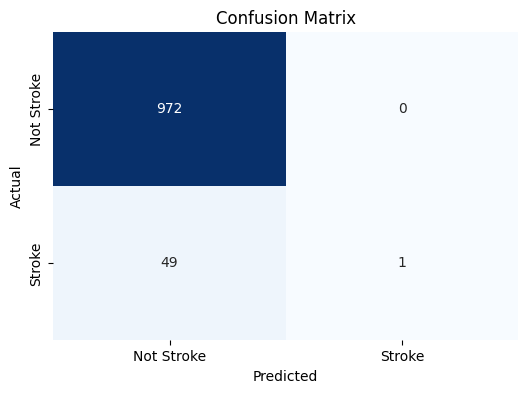


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.98       972
      Stroke       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022

ROC-AUC: 0.8422016460905349


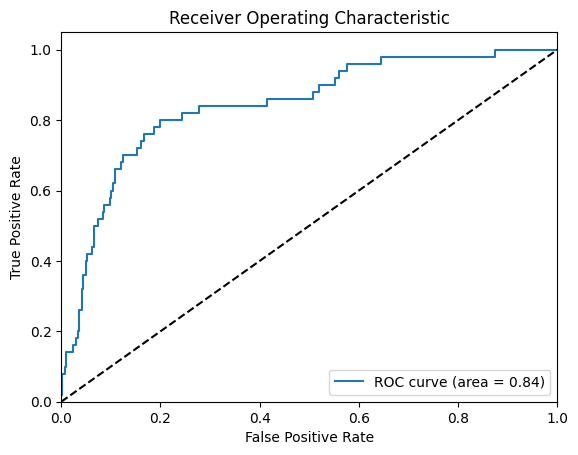

PR AUC: 0.27045630313141245


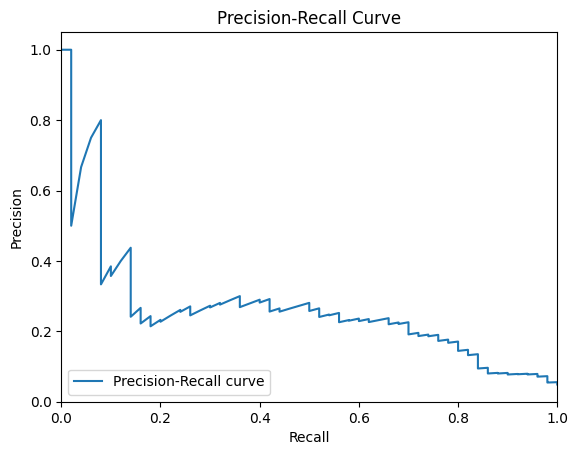

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
  8%|▊         | 1/13 [00:01<00:19,  1.61s/it]


Confusion Matrix:
 [[968   4]
 [ 49   1]]


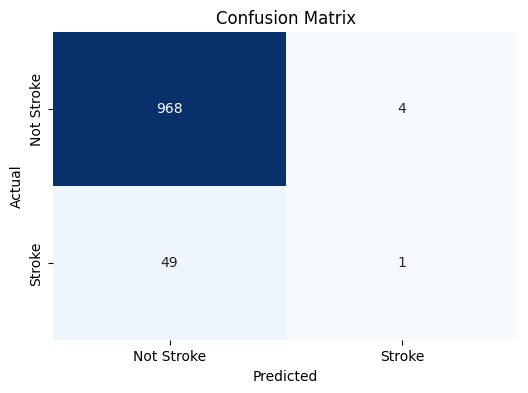


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.20      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.58      0.51      0.50      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.6137345679012345


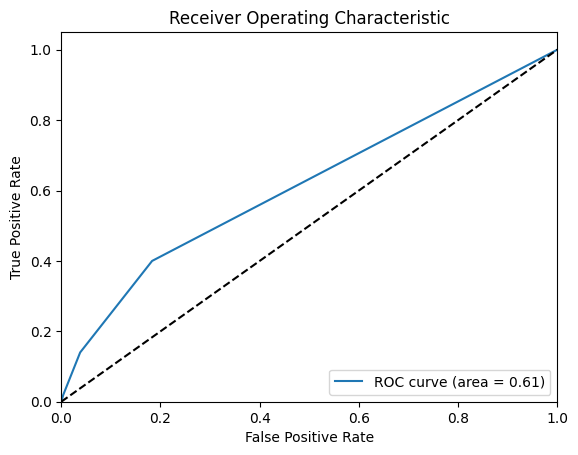

PR AUC: 0.07870774278993457


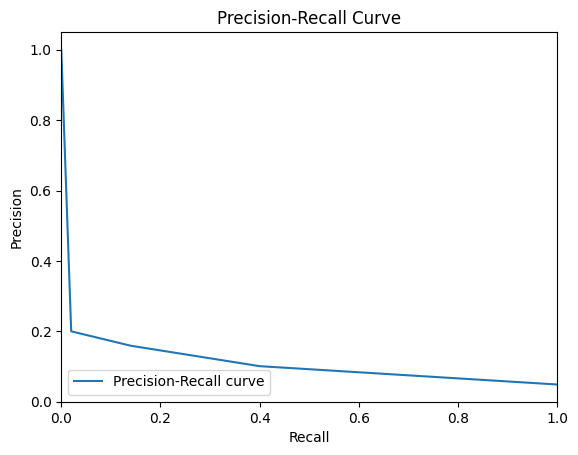

 15%|█▌        | 2/13 [00:03<00:16,  1.51s/it]


Confusion Matrix:
 [[972   0]
 [ 50   0]]


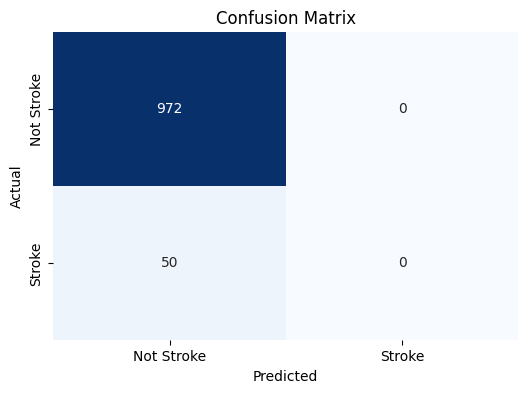


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.6190946502057613


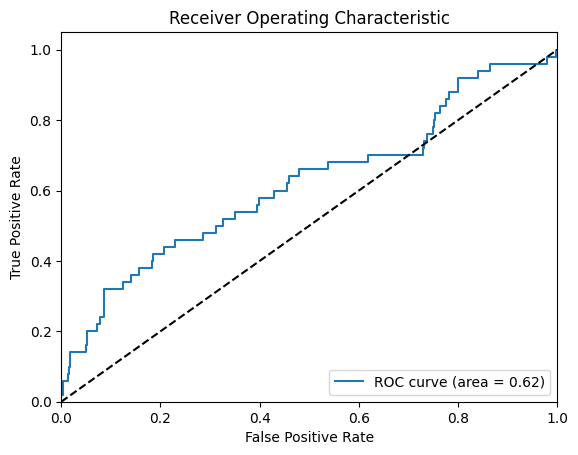

PR AUC: 0.12924197914738927


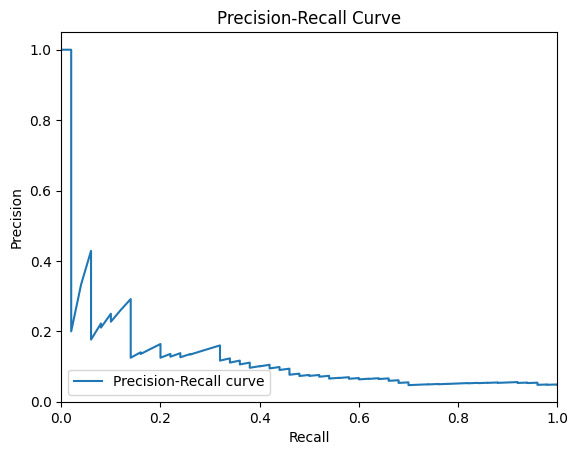

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 23%|██▎       | 3/13 [00:07<00:29,  2.90s/it]


Confusion Matrix:
 [[925  47]
 [ 40  10]]


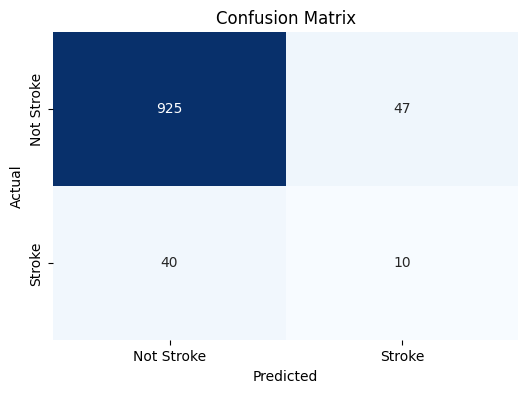


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.95      0.96       972
      Stroke       0.18      0.20      0.19        50

    accuracy                           0.91      1022
   macro avg       0.57      0.58      0.57      1022
weighted avg       0.92      0.91      0.92      1022

ROC-AUC: 0.5758230452674897


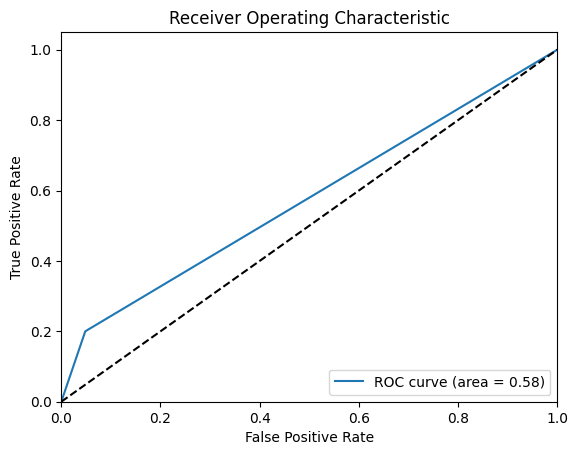

PR AUC: 0.0742266625467779


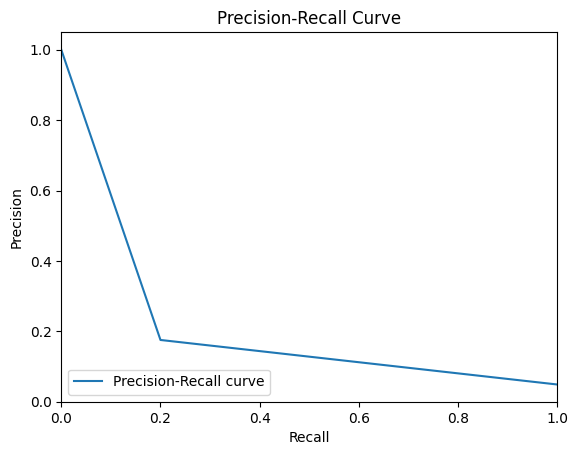

 31%|███       | 4/13 [00:08<00:20,  2.23s/it]


Confusion Matrix:
 [[141 831]
 [  1  49]]


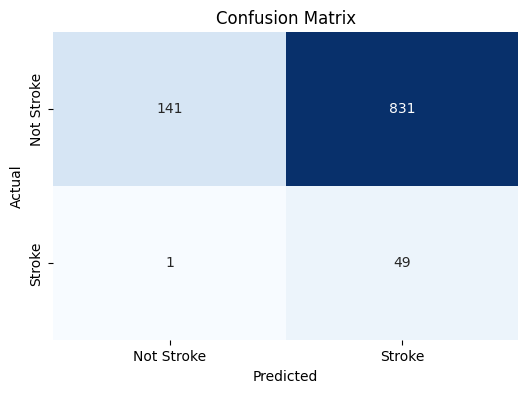


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      0.15      0.25       972
      Stroke       0.06      0.98      0.11        50

    accuracy                           0.19      1022
   macro avg       0.52      0.56      0.18      1022
weighted avg       0.95      0.19      0.25      1022

ROC-AUC: 0.7991975308641976


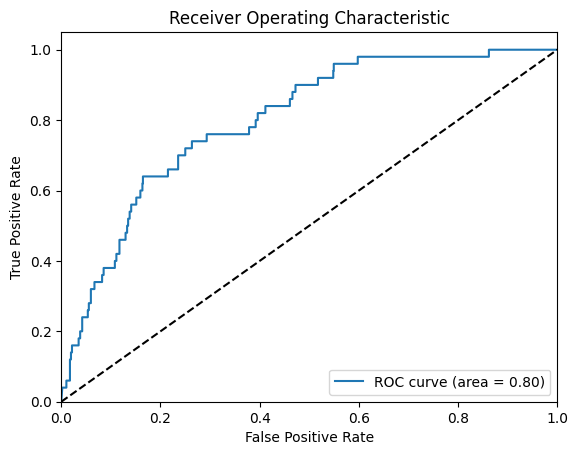

PR AUC: 0.1730787553400608


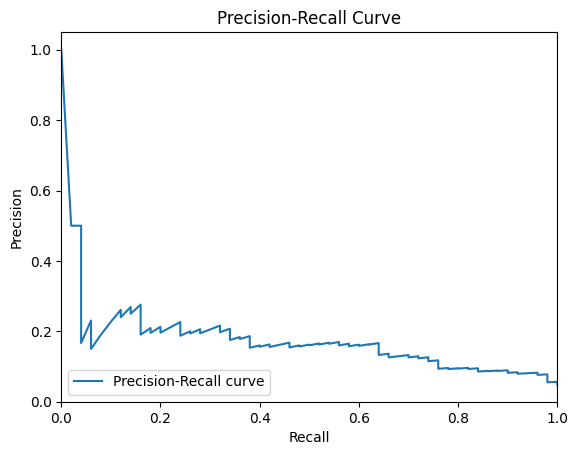

 38%|███▊      | 5/13 [00:09<00:14,  1.76s/it]


Confusion Matrix:
 [[970   2]
 [ 48   2]]


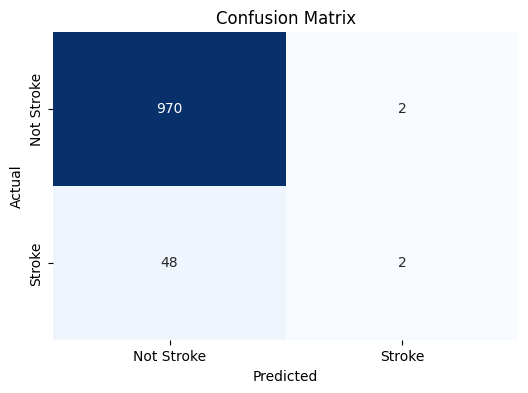


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.50      0.04      0.07        50

    accuracy                           0.95      1022
   macro avg       0.73      0.52      0.52      1022
weighted avg       0.93      0.95      0.93      1022

ROC-AUC: 0.7957818930041152


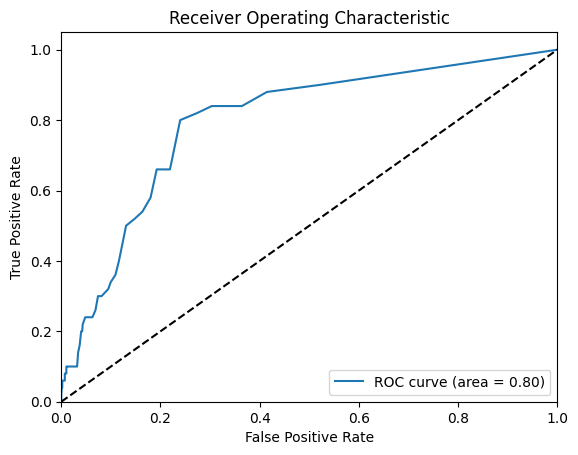

PR AUC: 0.18753655651783746


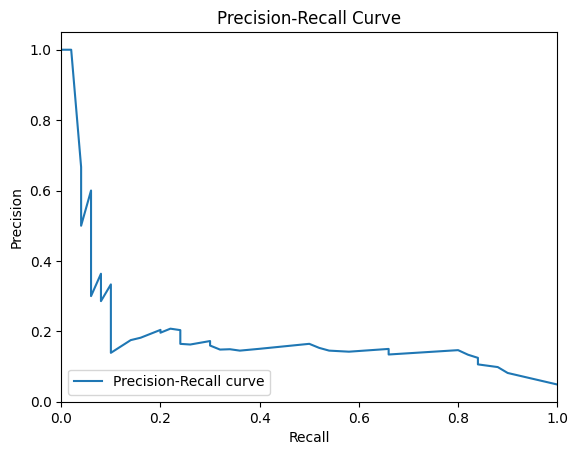

 46%|████▌     | 6/13 [00:12<00:14,  2.10s/it]


Confusion Matrix:
 [[962  10]
 [ 48   2]]


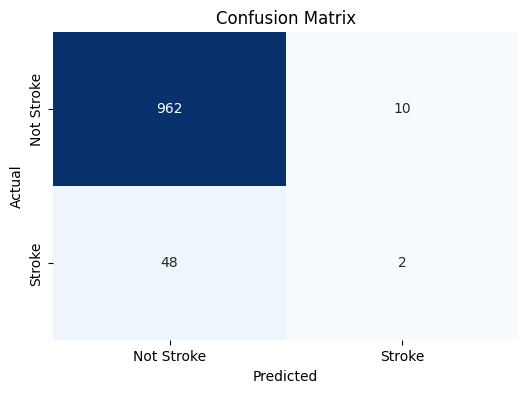


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.17      0.04      0.06        50

    accuracy                           0.94      1022
   macro avg       0.56      0.51      0.52      1022
weighted avg       0.91      0.94      0.93      1022

ROC-AUC: 0.7538477366255143


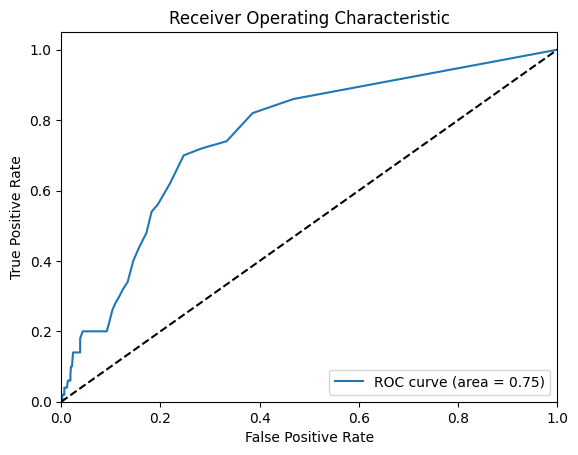

PR AUC: 0.12824913531292012


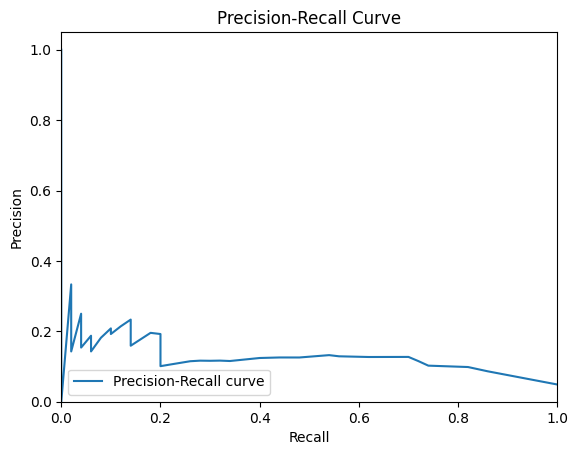

 54%|█████▍    | 7/13 [00:15<00:14,  2.37s/it]


Confusion Matrix:
 [[972   0]
 [ 50   0]]


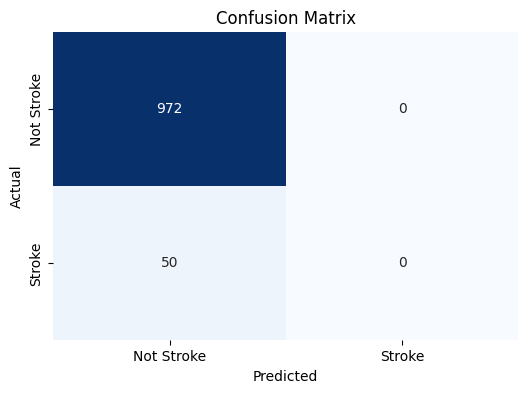


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.8287448559670783


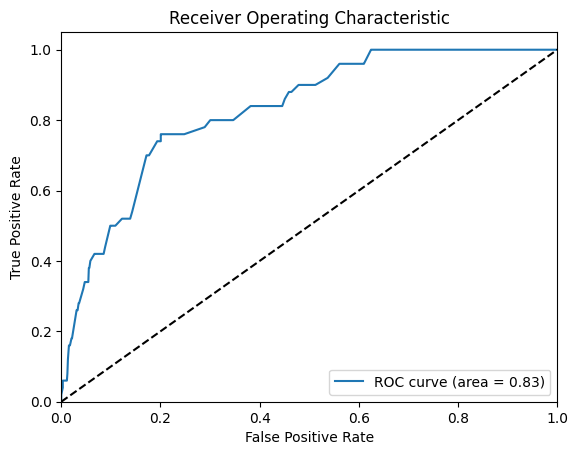

PR AUC: 0.22525228523943236


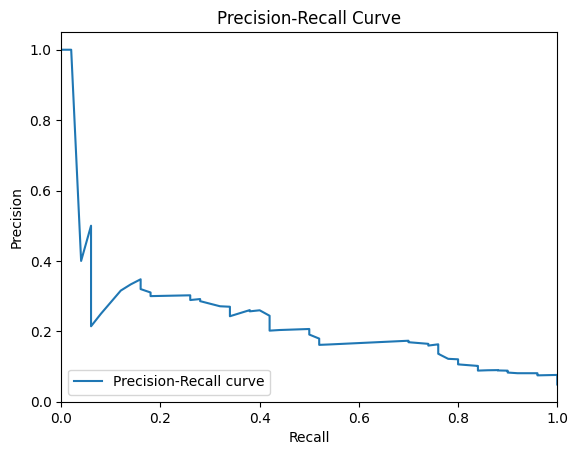

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 62%|██████▏   | 8/13 [00:17<00:10,  2.19s/it]


Confusion Matrix:
 [[970   2]
 [ 49   1]]


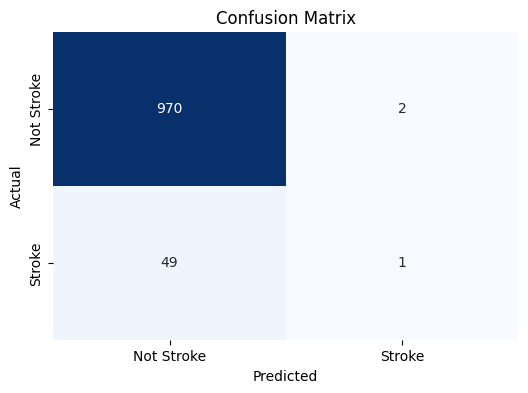


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.33      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.64      0.51      0.51      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.831820987654321


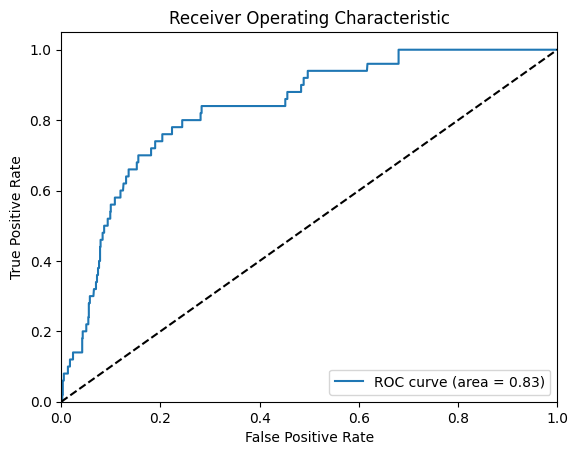

PR AUC: 0.19805319249166298


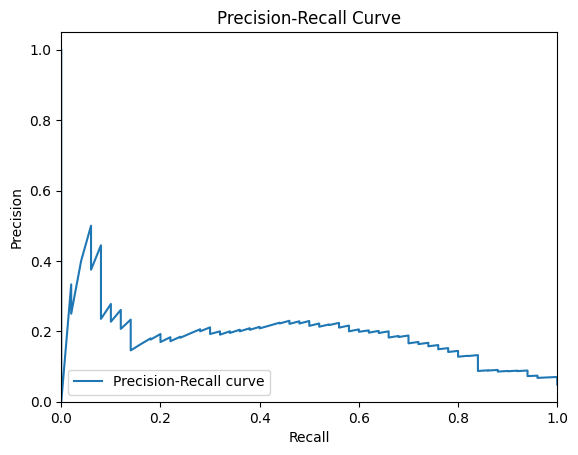

 69%|██████▉   | 9/13 [00:19<00:08,  2.11s/it]


Confusion Matrix:
 [[968   4]
 [ 49   1]]


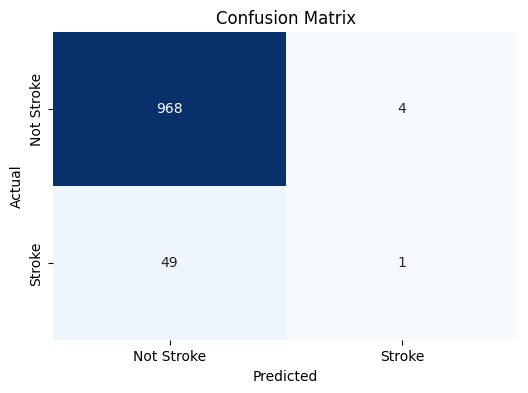


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.20      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.58      0.51      0.50      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8323045267489712


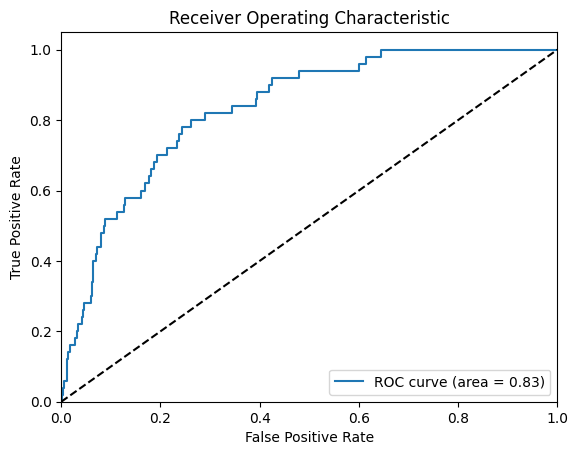

PR AUC: 0.19855029836913035


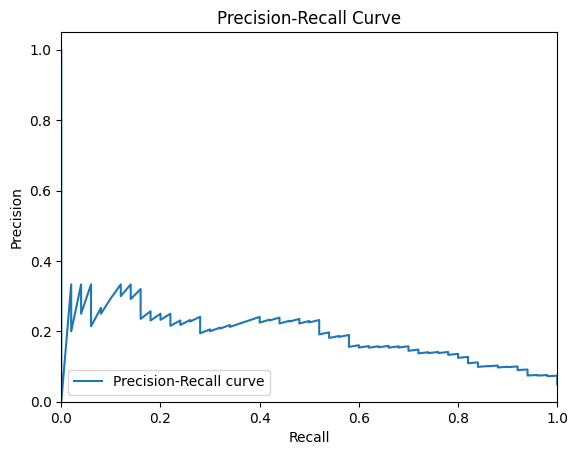

 77%|███████▋  | 10/13 [00:20<00:06,  2.01s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:14:43] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[964   8]
 [ 45   5]]


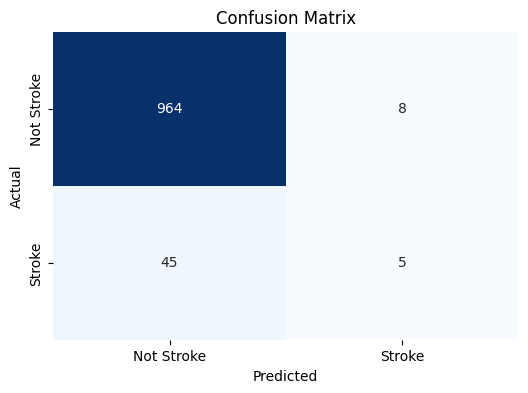


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.99      0.97       972
      Stroke       0.38      0.10      0.16        50

    accuracy                           0.95      1022
   macro avg       0.67      0.55      0.57      1022
weighted avg       0.93      0.95      0.93      1022

ROC-AUC: 0.7879423868312757


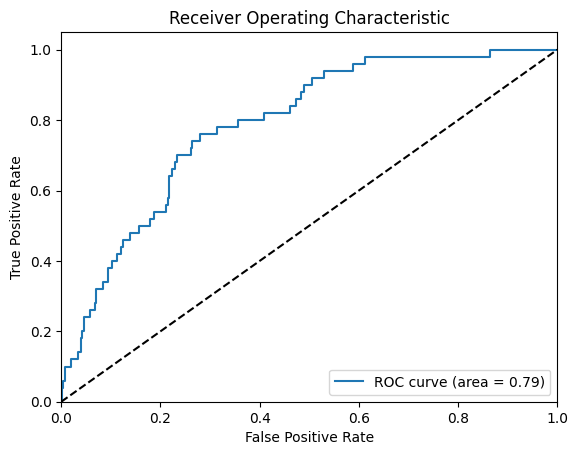

PR AUC: 0.1738600354166266


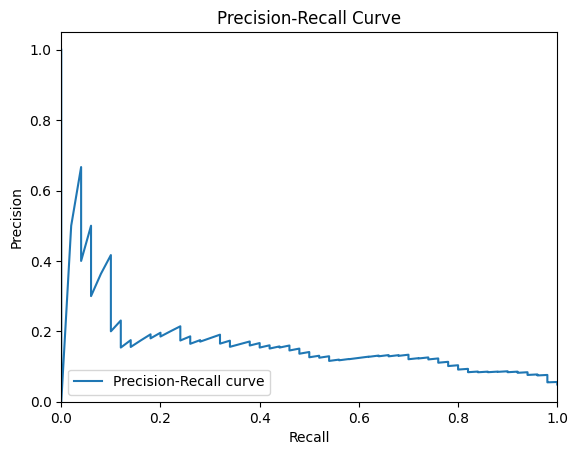

 85%|████████▍ | 11/13 [00:23<00:04,  2.12s/it]


Confusion Matrix:
 [[967   5]
 [ 46   4]]


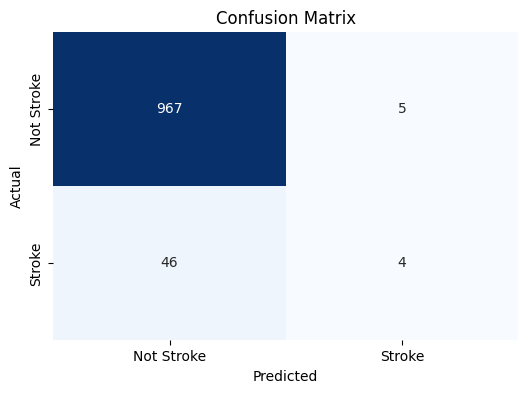


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.44      0.08      0.14        50

    accuracy                           0.95      1022
   macro avg       0.70      0.54      0.55      1022
weighted avg       0.93      0.95      0.93      1022

ROC-AUC: 0.8264197530864198


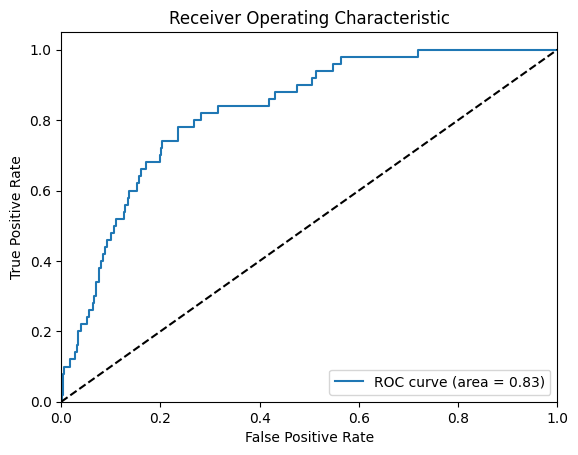

PR AUC: 0.1966282364242296


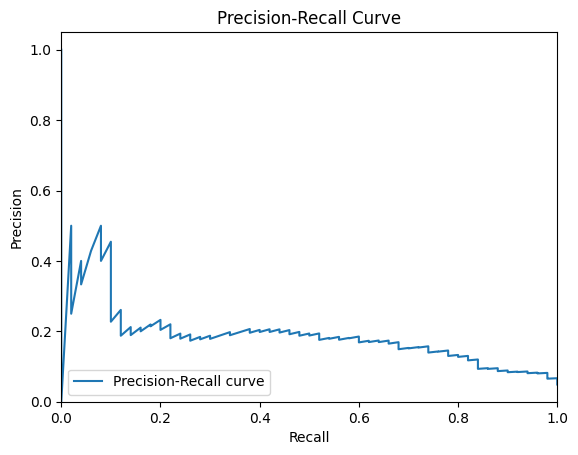

 92%|█████████▏| 12/13 [00:30<00:03,  3.65s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 199, number of negative: 3889
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001359 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 643
[LightGBM] [Info] Number of data points in the train set: 4088, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.048679 -> initscore=-2.972603
[LightGBM] [Info] Start training from score -2.972603

Confusion Matrix:
 [[963   9]
 [ 46   4]]


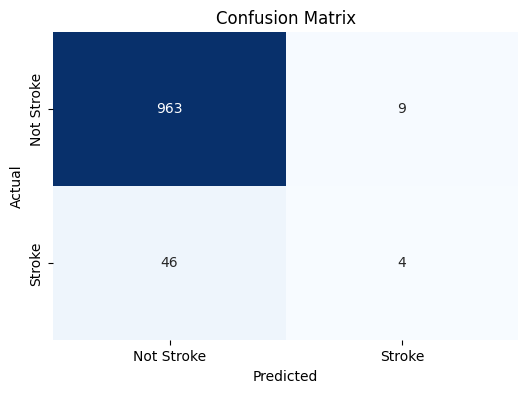


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.31      0.08      0.13        50

    accuracy                           0.95      1022
   macro avg       0.63      0.54      0.55      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8241152263374486


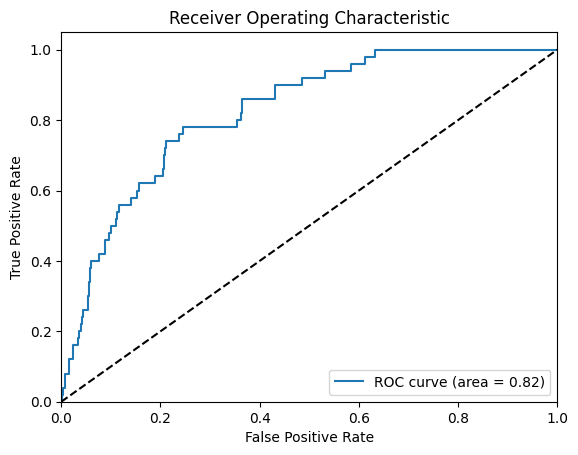

PR AUC: 0.19231592717301013


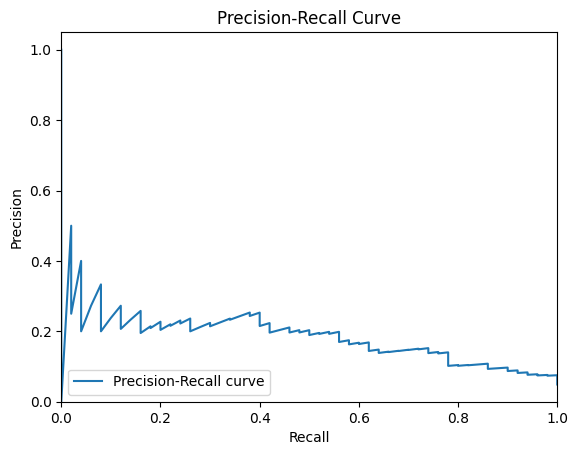

100%|██████████| 13/13 [00:31<00:00,  2.39s/it]


In [46]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:14:53] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[963   9]
 [ 45   5]]


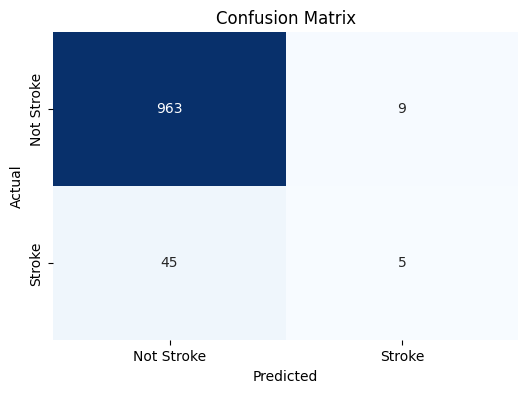


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.99      0.97       972
      Stroke       0.36      0.10      0.16        50

    accuracy                           0.95      1022
   macro avg       0.66      0.55      0.56      1022
weighted avg       0.93      0.95      0.93      1022

ROC-AUC: 0.8260699588477366


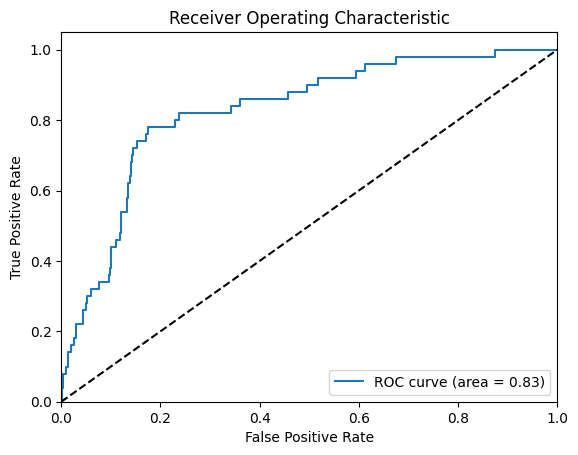

PR AUC: 0.21239301810708322


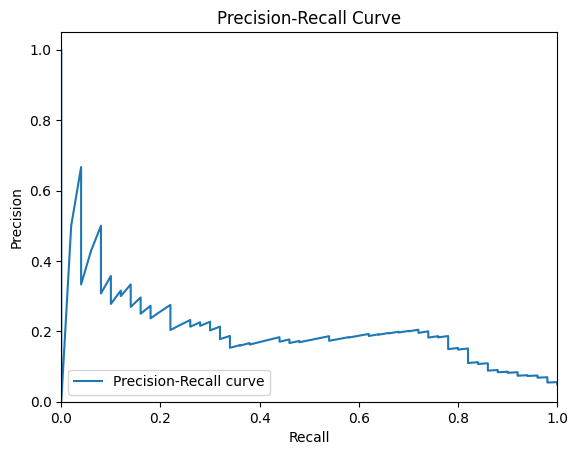

In [47]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:15:03] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[960  12]
 [ 46   4]]


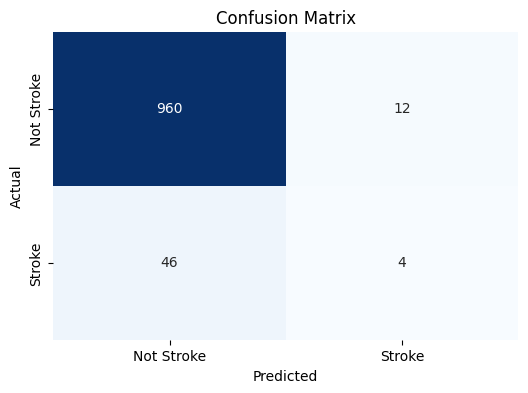


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.25      0.08      0.12        50

    accuracy                           0.94      1022
   macro avg       0.60      0.53      0.55      1022
weighted avg       0.92      0.94      0.93      1022

ROC-AUC: 0.7733333333333332


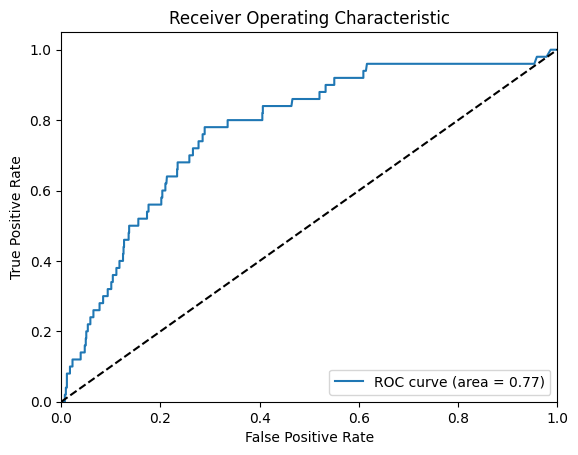

PR AUC: 0.13799306061478073


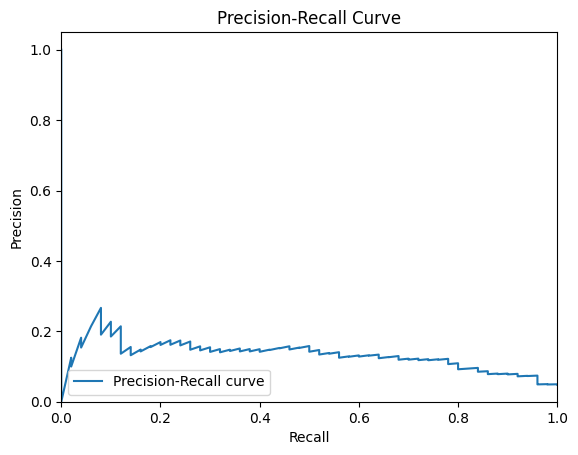

In [48]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [49]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [50]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Decision Tree,1.000000,0.914873,1.000000,0.175439,1.000000,0.20,1.000000,0.186916,1.000000,0.575823,0.575823,0.074227
XGBoost,0.997065,0.948141,1.000000,0.384615,0.939698,0.10,0.968912,0.158730,0.969849,0.545885,0.787942,0.173860
Voting Classifier,0.999755,0.947162,1.000000,0.357143,0.994975,0.10,0.997481,0.156250,0.997487,0.545370,0.826070,0.212393
CatBoost,0.976272,0.950098,0.990385,0.444444,0.517588,0.08,0.679868,0.135593,0.758665,0.537428,0.826420,0.196628
LightGBM,0.994863,0.946184,1.000000,0.307692,0.894472,0.08,0.944297,0.126984,0.947236,0.535370,0.824115,0.192316
Stacking Classifier,0.951076,0.943249,0.492063,0.250000,0.155779,0.08,0.236641,0.121212,0.573775,0.533827,0.773333,0.137993
Naive Bayes,0.187867,0.185910,0.056298,0.055682,0.994975,0.98,0.106566,0.105376,0.570771,0.562531,0.799198,0.173079
Random Forest,1.000000,0.951076,1.000000,0.500000,1.000000,0.04,1.000000,0.074074,1.000000,0.518971,0.795782,0.187537
Extra Trees,1.000000,0.943249,1.000000,0.166667,1.000000,0.04,1.000000,0.064516,1.000000,0.514856,0.753848,0.128249
Logistic Regression,0.951321,0.952055,0.000000,1.000000,0.000000,0.02,0.000000,0.039216,0.500000,0.510000,0.842202,0.270456


<Axes: >

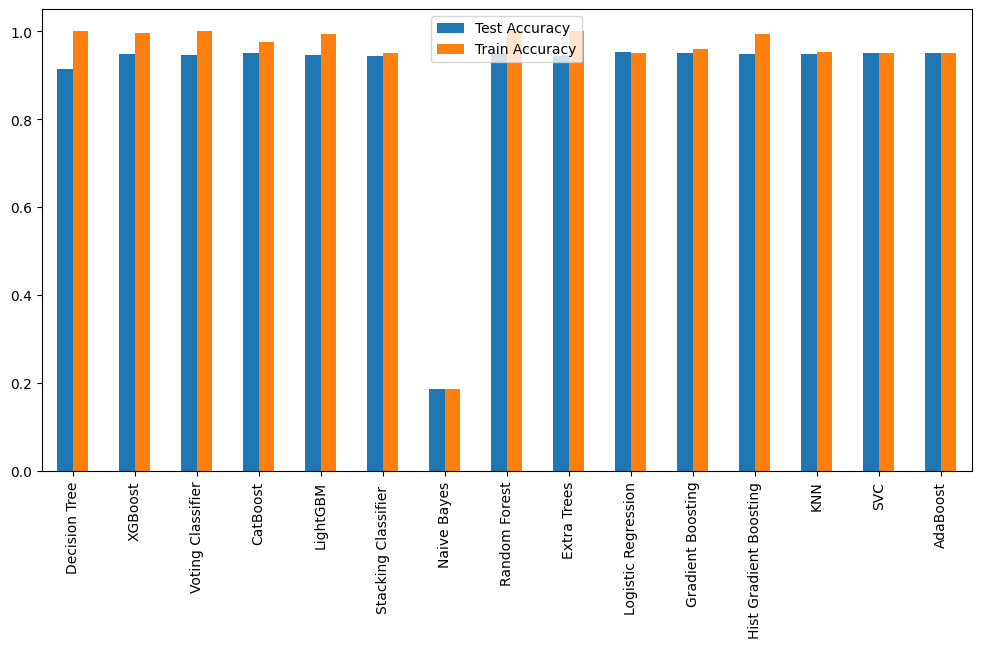

In [51]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

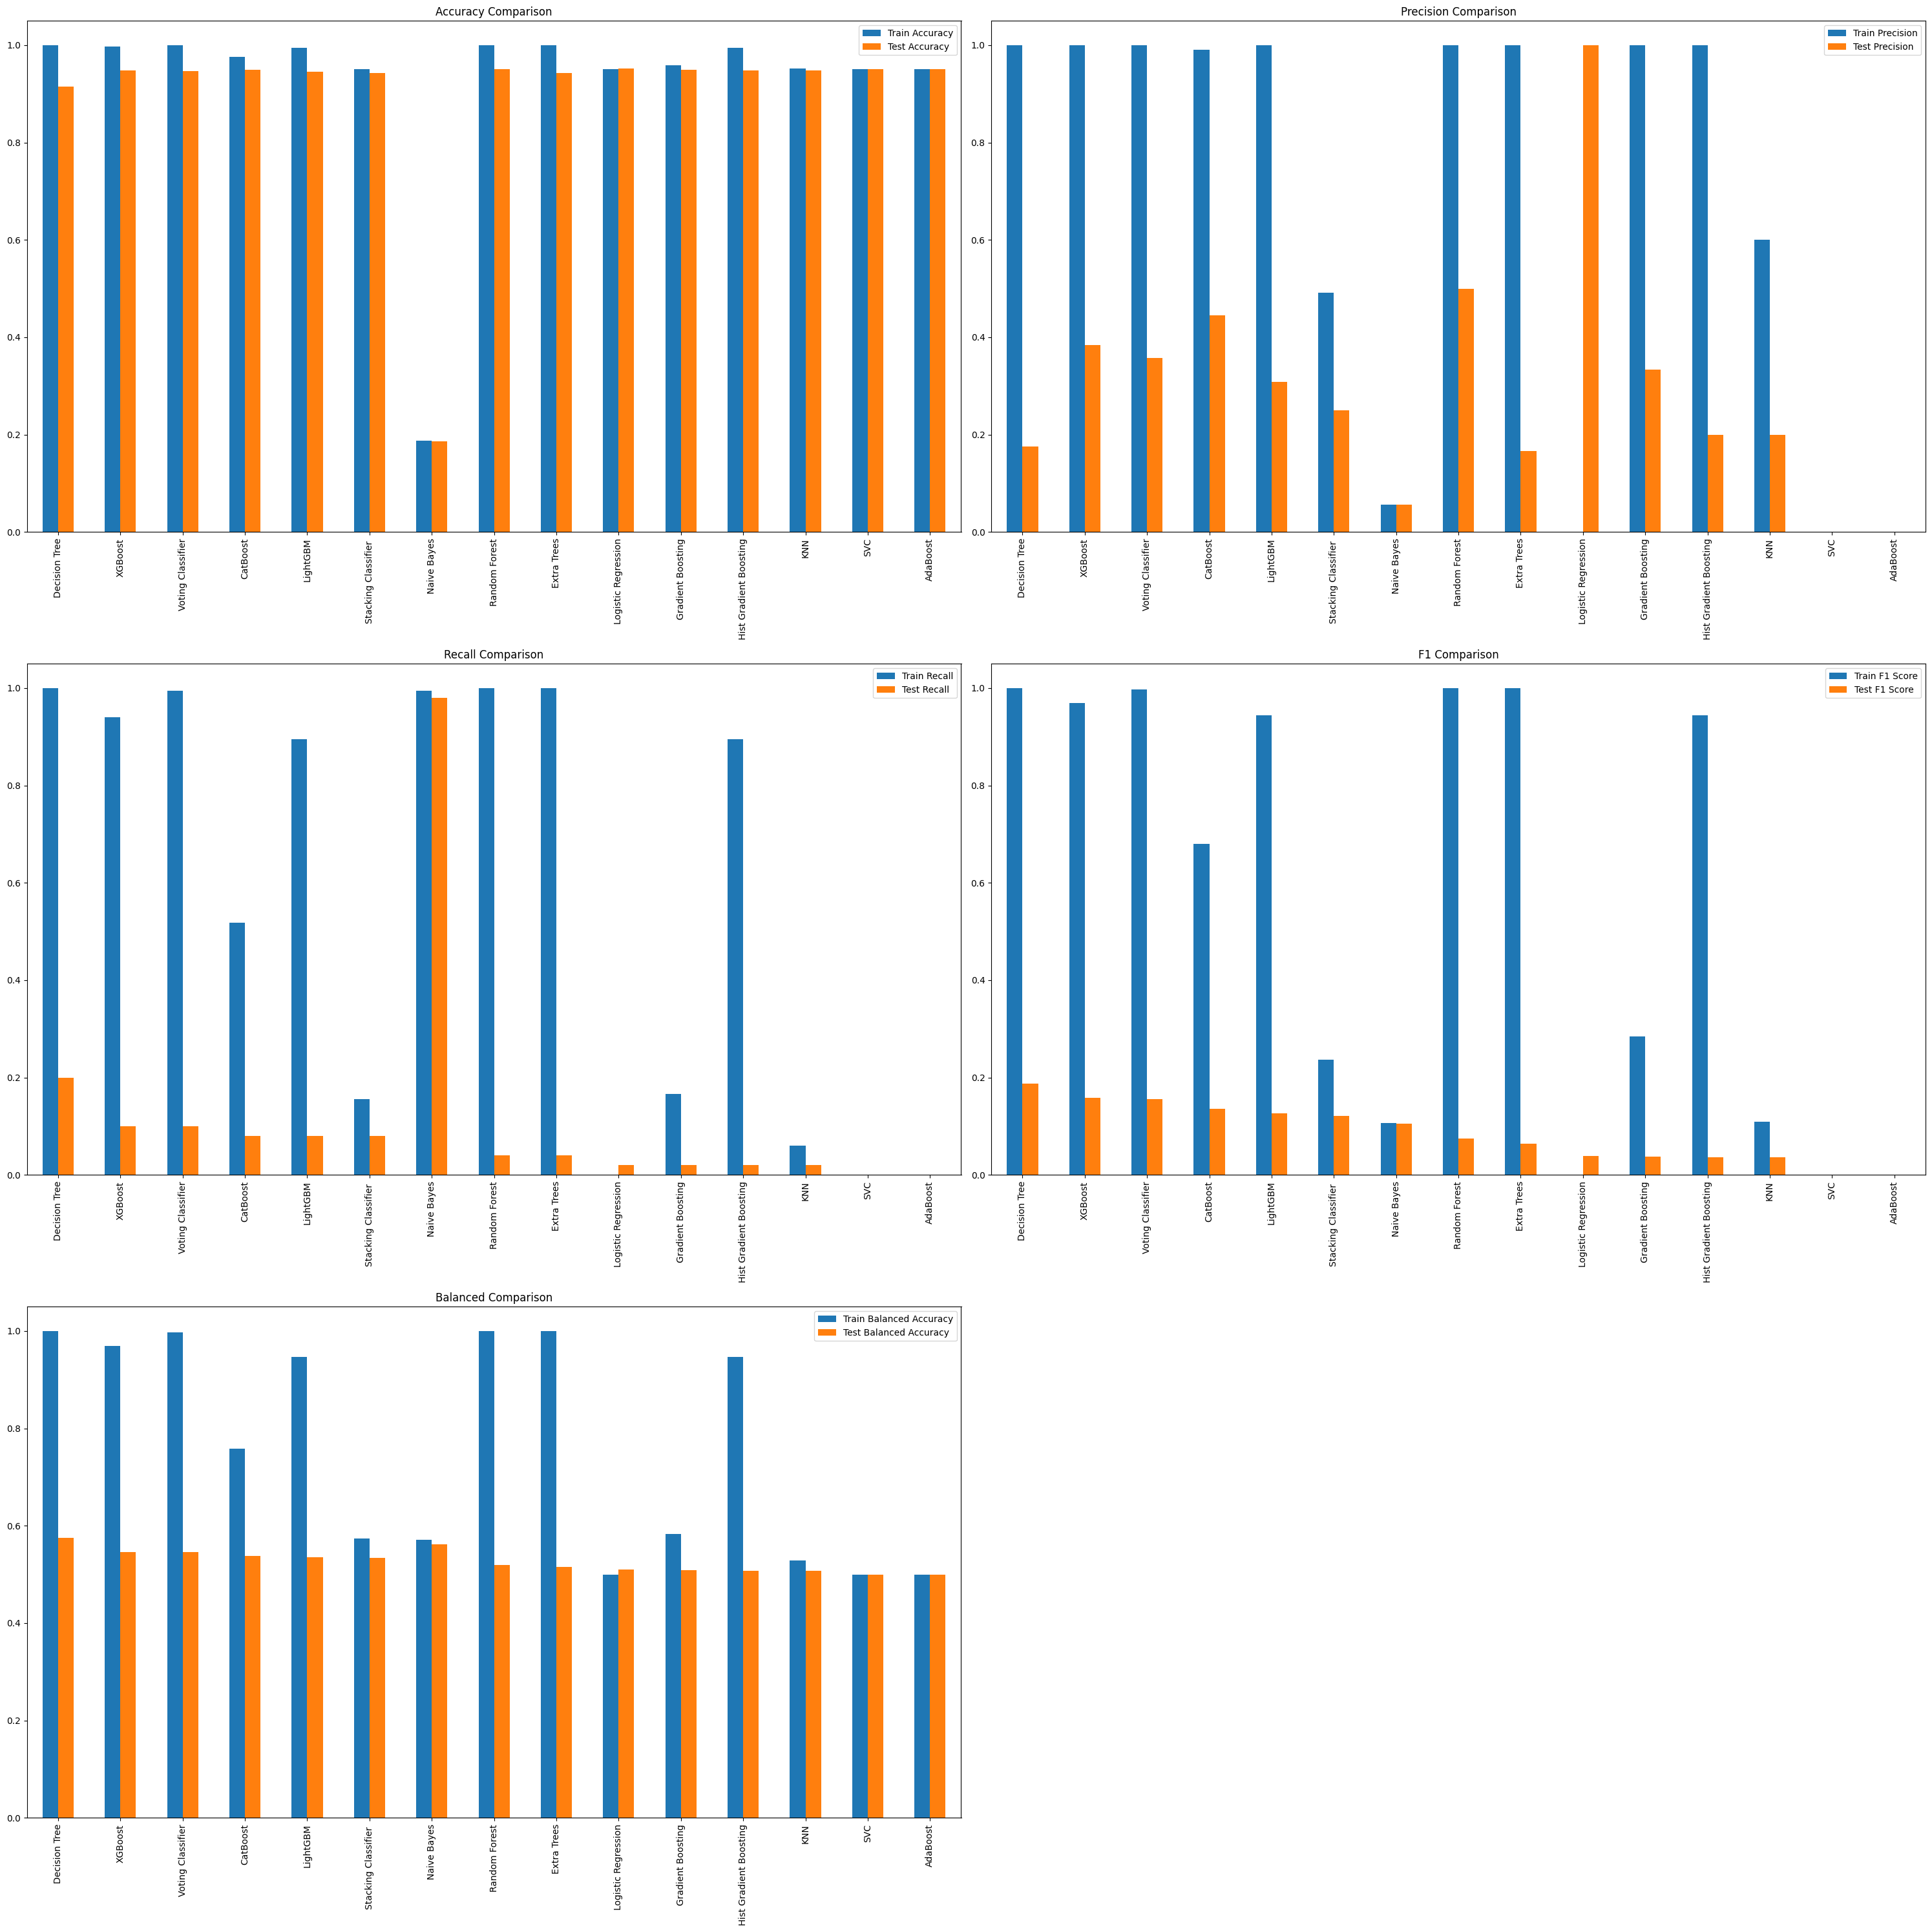

In [52]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()

**Note:** the table above shows how each model behaves on the test set with the default threshold (0.5). Models without class weights (KNN, Naive Bayes, AdaBoost, Gradient Boosting...) have a very low recall. To **choose** and **tune** the model we do not use the test set; we use cross-validation on the training data (next sections).

## 9. Model comparison with Cross-Validation (train data only)
Every model is evaluated with 5-fold stratified cross-validation using **PR-AUC (average precision)**, a metric that works well when the positive class is rare. A random model gets a PR-AUC equal to the stroke percentage (~0.05).

In [53]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=skf, scoring='average_precision')
    cv_scores[name] = scores.mean()

cv_df = pd.Series(cv_scores).sort_values(ascending=False).to_frame('CV PR-AUC')
print("Random-guess PR-AUC:", round(y_train.mean(), 3))
cv_df

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:15:21] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:15:21] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:15:22] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:15:22] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 159, number of negative: 3111
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000479 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 641
[LightGBM] [Info] Number of data points in the train set: 3270, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.048624 -> initscore=-2.973795
[LightGBM] [Info] Start training from score -2.973795
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 159, number of negative: 3111
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000474 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=

,CV PR-AUC
Gradient Boosting,0.202555
Logistic Regression,0.191726
Random Forest,0.178066
CatBoost,0.177831
LightGBM,0.176684
Hist Gradient Boosting,0.170715
AdaBoost,0.166429
XGBoost,0.161257
Naive Bayes,0.157555
Extra Trees,0.127121


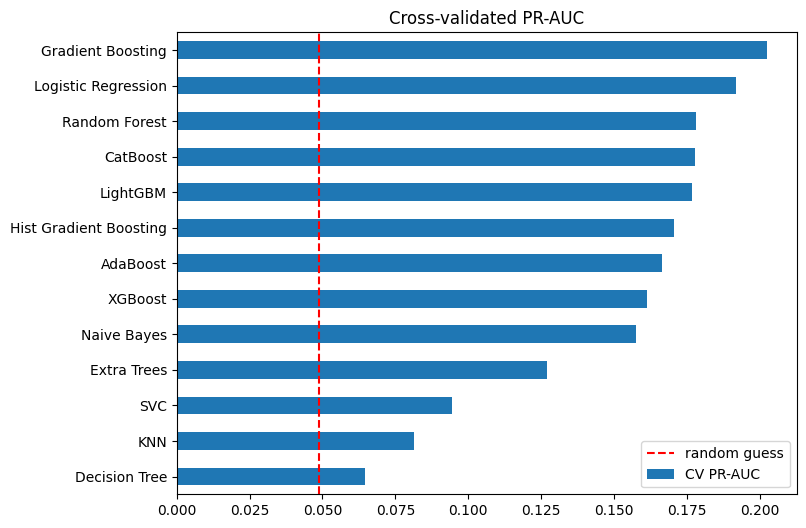

In [54]:
cv_df['CV PR-AUC'].sort_values().plot.barh(figsize=(8, 6))
plt.axvline(y_train.mean(), color='red', linestyle='--', label='random guess')
plt.title('Cross-validated PR-AUC')
plt.legend()
plt.show()

## 10. GridSearchCV on the best 3 models
We tune the top 3 models of the comparison. `GridSearchCV` uses cross-validation on the training data only (never the test set). For the models that support it, `class_weight` is part of the grid to deal with the imbalance.

In [55]:
param_grids = {
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10], 'class_weight': [None, 'balanced']},
    'KNN': {'n_neighbors': [5, 11, 21, 41], 'weights': ['uniform', 'distance']},
    'SVC': {'C': [0.1, 1, 10], 'class_weight': [None, 'balanced']},
    'Decision Tree': {'max_depth': [3, 5, 8, None], 'min_samples_leaf': [1, 10, 30], 'class_weight': [None, 'balanced']},
    'Naive Bayes': {'var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3]},
    'Random Forest': {'max_depth': [4, 8, None], 'min_samples_leaf': [1, 5, 10], 'class_weight': [None, 'balanced_subsample']},
    'Extra Trees': {'max_depth': [4, 8, None], 'min_samples_leaf': [1, 5, 10], 'class_weight': [None, 'balanced_subsample']},
    'AdaBoost': {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.1, 1.0]},
    'Gradient Boosting': {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3]},
    'Hist Gradient Boosting': {'learning_rate': [0.03, 0.1], 'max_depth': [3, None], 'class_weight': [None, 'balanced']},
    'XGBoost': {'n_estimators': [100, 300], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.1]},
    'CatBoost': {'iterations': [200, 500], 'depth': [4, 6], 'learning_rate': [0.03, 0.1]},
    'LightGBM': {'n_estimators': [100, 300], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.1]},
}

top3 = cv_df.head(3).index.tolist()
print("Models to tune:", top3)

tuned = {}
summary = []
for name in top3:
    grid = GridSearchCV(models[name], param_grids[name], cv=skf, scoring='average_precision', n_jobs=-1)
    grid.fit(X_train, y_train)
    tuned[name] = grid
    print(f"\n{name}")
    print("  best_params_:", grid.best_params_)
    print("  best_score_ :", round(grid.best_score_, 4))
    summary.append([name, cv_df.loc[name, 'CV PR-AUC'], grid.best_score_])

tuning_df = pd.DataFrame(summary, columns=['Model', 'Before tuning', 'After tuning (best_score_)']).set_index('Model')
tuning_df

Models to tune: ['Gradient Boosting', 'Logistic Regression', 'Random Forest']

Gradient Boosting
  best_params_: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
  best_score_ : 0.2162

Logistic Regression
  best_params_: {'C': 1, 'class_weight': 'balanced'}
  best_score_ : 0.1934

Random Forest
  best_params_: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 10}
  best_score_ : 0.2026


,Before tuning,After tuning (best_score_)
Model,,
Gradient Boosting,0.202555,0.216215
Logistic Regression,0.191726,0.193419
Random Forest,0.178066,0.202633


## 11. Final model as a Pipeline (for deployment)
The best tuned model is selected by `best_score_`. For the app we need a model that accepts the **raw** patient data, so we build a `Pipeline` + `ColumnTransformer` that does the imputation, scaling and encoding by itself (fitted on the training data only) and then the model with its best parameters.

In [56]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

best_name = tuning_df['After tuning (best_score_)'].idxmax()
best_model = tuned[best_name].best_estimator_
print("Best model:", best_name, tuned[best_name].best_params_)

# raw (not encoded) data with the same train/test rows
X_raw = df.drop(columns=['stroke', 'id'], errors='ignore')
X_raw_train, X_raw_test = X_raw.loc[X_train.index], X_raw.loc[X_test.index]

num_cols = ['age', 'avg_glucose_level', 'bmi']
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
bin_cols = ['hypertension', 'heart_disease']

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('bin', 'passthrough', bin_cols),
])

final_pipe = Pipeline([('prep', preprocessor), ('model', clone(best_model))])
final_pipe.fit(X_raw_train, y_train)

Best model: Gradient Boosting {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'avg_glucose_level',
                                                   'bmi']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['gender', 'ever_married',
                                                   'work_type',
                                                   'Residence_type',
                                                   'smoking_status']),
                                                 ('bin', 'passthrough',
                                                  ['hypertension',
                                                   'heart_disease'])])),
                ('model',
                 GradientBoostingClassifier(learning_rate=0.05,
                                            random_state=1))])

### Decision threshold
The default threshold 0.5 gives a very low recall on imbalanced data. We choose the threshold that maximizes **F2** (recall counts twice as much as precision) using cross-validated predictions on the **training** data only.

In [57]:
from sklearn.model_selection import cross_val_predict

oof_proba = cross_val_predict(final_pipe, X_raw_train, y_train, cv=skf, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f2 = 5 * prec[:-1] * rec[:-1] / (4 * prec[:-1] + rec[:-1] + 1e-12)
best_thr = float(thr[np.argmax(f2)])
print("Chosen threshold:", round(best_thr, 3))

Chosen threshold: 0.069


## 12. Final evaluation on the test set (used once)

--- Classification Report (tuned threshold) ---
              precision    recall  f1-score   support

  Not Stroke       0.99      0.81      0.89       972
      Stroke       0.17      0.78      0.28        50

    accuracy                           0.80      1022
   macro avg       0.58      0.79      0.58      1022
weighted avg       0.95      0.80      0.86      1022

ROC-AUC: 0.836 | PR-AUC: 0.214 | random PR-AUC: 0.049


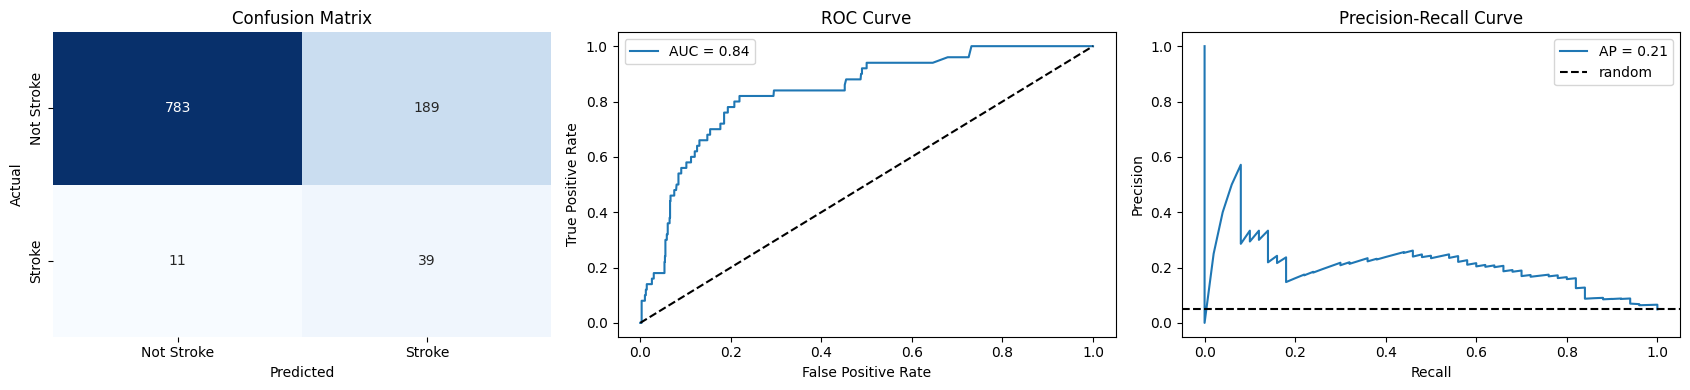

In [58]:
test_proba = final_pipe.predict_proba(X_raw_test)[:, 1]
y_final = (test_proba >= best_thr).astype(int)

print("--- Classification Report (tuned threshold) ---")
print(classification_report(y_test, y_final, target_names=['Not Stroke', 'Stroke'], zero_division=0))

roc_auc = roc_auc_score(y_test, test_proba)
pr_auc = average_precision_score(y_test, test_proba)
print("ROC-AUC:", round(roc_auc, 3), "| PR-AUC:", round(pr_auc, 3), "| random PR-AUC:", round(y_test.mean(), 3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

cm = confusion_matrix(y_test, y_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Not Stroke', 'Stroke'], yticklabels=['Not Stroke', 'Stroke'])
axes[0].set_title('Confusion Matrix'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}'); axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('ROC Curve'); axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate'); axes[1].legend()

p_, r_, _ = precision_recall_curve(y_test, test_proba)
axes[2].plot(r_, p_, label=f'AP = {pr_auc:.2f}'); axes[2].axhline(y_test.mean(), color='k', linestyle='--', label='random')
axes[2].set_title('Precision-Recall Curve'); axes[2].set_xlabel('Recall'); axes[2].set_ylabel('Precision'); axes[2].legend()
plt.tight_layout()
plt.show()

In [59]:
tn, fp, fn, tp = cm.ravel()
print(f"Model: {best_name} | threshold: {best_thr:.2f}")
print(f"- Finds {tp} of {tp + fn} real stroke cases (recall = {tp / (tp + fn):.0%}) and misses {fn}.")
print(f"- Of {tp + fp} patients flagged as high risk, {tp} really had a stroke (precision = {tp / max(tp + fp, 1):.0%}).")
print(f"- ROC-AUC = {roc_auc:.2f}, PR-AUC = {pr_auc:.2f} (random guessing = {y_test.mean():.2f}).")

Model: Gradient Boosting | threshold: 0.07
- Finds 39 of 50 real stroke cases (recall = 78%) and misses 11.
- Of 228 patients flagged as high risk, 39 really had a stroke (precision = 17%).
- ROC-AUC = 0.84, PR-AUC = 0.21 (random guessing = 0.05).


**Interpretation**
- **Recall (stroke):** the share of real stroke patients that the model catches; the most important metric here.
- **Precision (stroke):** low, because stroke is rare (~5%): many alarms are false. This is acceptable for screening (a false alarm only needs a check-up), but it must be stated clearly.
- **Confusion matrix:** the bottom-left cell (missed strokes) is the error we want to keep small.
- **ROC-AUC vs PR-AUC:** ROC-AUC looks optimistic on imbalanced data, so PR-AUC compared with the random line (~0.05) is the honest measure.
- This is a binary problem, so no multiclass averaging is needed.

## 13. Save the model (used by `app.py` for the Gradio deployment)

In [60]:
import joblib, sklearn
os.makedirs('model', exist_ok=True)

joblib.dump({'pipeline': final_pipe, 'threshold': best_thr,
             'model_name': best_name, 'features': list(X_raw.columns)},
            'model/stroke_model.joblib')

print("Saved model/stroke_model.joblib")
print("Put this in requirements.txt:  scikit-learn==" + sklearn.__version__)

Saved model/stroke_model.joblib
Put this in requirements.txt:  scikit-learn==1.6.1
